# Certamen 2 · Reglas de asociación y recomendador de lecturas
## Base: *goodbooks-10k* — "lectores a quienes les gustó este libro también disfrutaron…"

**Grupo:** X  **Integrantes:** ______________________  **Docente:** Danilo Gómez Correa

Este notebook adapta la guía de clase (*Groceries*) a una base de **lectores y libros**.
Se ejecuta de principio a fin en Google Colab, con semilla fija (`SEMILLA = 42`).

**Contenido**
1. Problema y base de datos
2. Limpieza y transacciones
3. Exploración
4. Itemsets y reglas
5. Fisher, redundantes y consulta dirigida
6. Recomendador
7. Evaluación offline
8. Hallazgos y recomendaciones
9. Exportación de CSV para el dashboard

## 0. Preparación del entorno

In [1]:
# Librerías que no vienen en Colab. Plotly, scipy y statsmodels ya están instaladas.
%pip install -q mlxtend==0.25.0 pyvis==0.3.2

Note: you may need to restart the kernel to use updated packages.


In [2]:
import re
import time
import html
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import plotly.express as px
from pyvis.network import Network
from IPython.display import HTML, display
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

warnings.filterwarnings("ignore")

# Configuración de visualización (igual que en la guía)
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.max_colwidth", 80)
plt.rcParams["figure.dpi"] = 110

# Paleta del proyecto (temática biblioteca)
AZUL = "#1f3a5f"
GRIS = "#6b7280"
ROJO = "#b23a48"

# Semilla fija para que todo sea reproducible
SEMILLA = 42

### Funciones auxiliares (de la guía)
`mlxtend` guarda antecedentes y consecuentes como `frozenset`; `tabla_reglas` los deja legibles: `{A} ⇒ {B}`.

In [3]:
def texto_itemset(itemset):
    # Convierte un frozenset en texto ordenado, por ejemplo: {1984, Animal Farm}
    return "{" + ", ".join(sorted(itemset)) + "}"


def tabla_reglas(reglas):
    # Tabla limpia con las medidas del curso, ordenada por lift
    tabla = pd.DataFrame({
        "regla": reglas["antecedents"].apply(texto_itemset) + " ⇒ " + reglas["consequents"].apply(texto_itemset),
        "soporte": reglas["support"],
        "confianza": reglas["confidence"],
        "lift": reglas["lift"],
        "leverage": reglas["leverage"],
        "conviccion": reglas["conviction"],
    })
    return tabla.sort_values("lift", ascending=False).reset_index(drop=True)

## 1. Problema y base de datos

| | |
|---|---|
| **Base** | *goodbooks-10k* (Zając, 2017) — calificaciones de 1 a 5 estrellas de los 10.000 libros más populares de Goodreads |
| **Fuente** | https://github.com/zygmuntz/goodbooks-10k |
| **Licencia** | CC BY-SA 4.0 (indicada en el repositorio original) |
| **Tamaño original** | 5.976.479 calificaciones · 53.424 usuarios · 10.000 libros |
| **Transacción** | un **lector** (usuario de Goodreads) |
| **Ítem** | un **libro que le gustó**: lo calificó con **4 o 5 estrellas** |

**Problema y decisión que apoya.** Una biblioteca, un club de lectura o una librería quiere sugerir la
**próxima lectura**: *"a los lectores que les gustó este libro también les gustó…"*.
El recomendador sirve para armar la sección *"Te puede gustar"* de un catálogo, planificar préstamos
(qué ejemplares tener disponibles juntos) y armar paquetes o listas de lectura.

**Por qué ≥ 4 estrellas.** Una calificación de 1–3 indica que el libro se leyó pero **no** necesariamente gustó.
Para recomendar, nos interesa la co-ocurrencia de libros **bien evaluados** (como MovieLens con nota ≥ 4).

In [4]:
# Carga directa desde GitHub (igual que Groceries en la guía): no hay que subir archivos
URL_BASE = "https://raw.githubusercontent.com/zygmuntz/goodbooks-10k/master/"

calificaciones = pd.read_csv(URL_BASE + "ratings.csv")   # user_id, book_id, rating
libros = pd.read_csv(URL_BASE + "books.csv")             # book_id, title, authors, ...

print(f"Calificaciones: {len(calificaciones):,}")
print(f"Usuarios: {calificaciones['user_id'].nunique():,} | Libros: {calificaciones['book_id'].nunique():,}")
calificaciones.head()

Calificaciones: 5,976,479
Usuarios: 53,424 | Libros: 10,000


,user_id,book_id,rating
0,1,258,5
1,2,4081,4
2,2,260,5
3,2,9296,5
4,2,2318,3


## 2. Limpieza y transacciones

Pasos:
1. **Nulos, duplicados y registros inválidos** (calificaciones fuera de 1–5, libros sin ficha).
2. **Normalización de nombres**: el título trae la saga entre paréntesis
   (*"Catching Fire (The Hunger Games, #2)"*); la quitamos para que las etiquetas sean legibles.
3. **Binarización**: el lector "tiene" el libro si lo calificó con 4 o 5.
4. **Reducción de ítems**: 10.000 libros es una cola larga extrema (casi todas las celdas vacías).
   Nos quedamos con los **100 libros más gustados**, que concentran la mayor parte de la actividad.
5. **Muestra de lectores**: tomamos **10.000 lectores al azar** (semilla 42) para que todo el notebook
   (Fisher, evaluación leave-one-out) corra en pocos minutos en Colab. Es la misma idea que el enunciado
   sugiere para Instacart (*"usar una muestra de pedidos"*).

In [5]:
# 2.1 Nulos, duplicados y valores inválidos
print("Nulos por columna:\n", calificaciones.isna().sum(), sep="")
print(f"Duplicados (mismo usuario y libro): {calificaciones.duplicated(['user_id', 'book_id']).sum()}")
print(f"Calificaciones fuera de 1–5: {(~calificaciones['rating'].between(1, 5)).sum()}")

calificaciones = (calificaciones
                  .dropna()
                  .drop_duplicates(["user_id", "book_id"])
                  .query("1 <= rating <= 5"))

# Libros sin ficha en books.csv (no podríamos mostrar su título)
sin_ficha = ~calificaciones["book_id"].isin(libros["book_id"])
print(f"Calificaciones de libros sin ficha: {sin_ficha.sum()}")
calificaciones = calificaciones[~sin_ficha]
print(f"Calificaciones tras la limpieza: {len(calificaciones):,}")

Nulos por columna:
user_id    0
book_id    0
rating     0
dtype: int64


Duplicados (mismo usuario y libro): 0
Calificaciones fuera de 1–5: 0


Calificaciones de libros sin ficha: 0
Calificaciones tras la limpieza: 5,976,479


In [6]:
# 2.2 Normalización de nombres: quitamos el paréntesis final con la saga y los espacios sobrantes
def nombre_corto(titulo):
    return re.sub(r"\s*\(.*?\)\s*$", "", str(titulo)).strip()

libros["libro"] = libros["title"].apply(nombre_corto)
libros["autor"] = libros["authors"].str.split(",").str[0].str.strip()   # primer autor

print(libros[["title", "libro", "autor"]].head(8).to_string(index=False))

                                                   title                                 libro               autor
                 The Hunger Games (The Hunger Games, #1)                      The Hunger Games     Suzanne Collins
Harry Potter and the Sorcerer's Stone (Harry Potter, #1) Harry Potter and the Sorcerer's Stone        J.K. Rowling
                                 Twilight (Twilight, #1)                              Twilight     Stephenie Meyer
                                   To Kill a Mockingbird                 To Kill a Mockingbird          Harper Lee
                                        The Great Gatsby                      The Great Gatsby F. Scott Fitzgerald
                                  The Fault in Our Stars                The Fault in Our Stars          John Green
                                              The Hobbit                            The Hobbit      J.R.R. Tolkien
                                  The Catcher in the Rye                The Catc

In [7]:
# 2.3 Binarización: solo los libros que le gustaron al lector (4 o 5 estrellas)
gustados = calificaciones[calificaciones["rating"] >= 4]
print(f"Calificaciones ≥ 4: {len(gustados):,} de {len(calificaciones):,} ({len(gustados) / len(calificaciones):.1%})")

# 2.4 Muestra de 10.000 lectores con semilla fija
generador = np.random.default_rng(SEMILLA)
lectores_muestra = generador.choice(gustados["user_id"].unique(), size=10_000, replace=False)

# 2.5 Catálogo: los 100 libros que más lectores calificaron con ≥ 4
N_LIBROS = 100
catalogo = gustados["book_id"].value_counts().head(N_LIBROS).index

lecturas = (gustados[gustados["user_id"].isin(lectores_muestra) & gustados["book_id"].isin(catalogo)]
            .merge(libros[["book_id", "libro", "autor"]], on="book_id"))

# Verificamos que los nombres cortos no choquen dentro del catálogo
assert lecturas.groupby("libro")["book_id"].nunique().max() == 1, "Hay títulos repetidos"
print(f"Formato largo (lector, libro): {len(lecturas):,} filas")
lecturas.head()

Calificaciones ≥ 4: 4,122,111 de 5,976,479 (69.0%)

Formato largo (lector, libro): 138,718 filas


,user_id,book_id,rating,libro,autor
0,43,8,4,The Catcher in the Rye,J.D. Salinger
1,66,35,4,The Alchemist,Paulo Coelho
2,54,81,5,The Glass Castle,Jeannette Walls
3,75,11,5,The Kite Runner,Khaled Hosseini
4,75,22,4,The Lovely Bones,Alice Sebold


In [8]:
# 2.6 Formato largo → canastas con groupby (una lista de libros por lector)
canastas = lecturas.groupby("user_id")["libro"].apply(lambda x: sorted(set(x)))
canastas = canastas[canastas.apply(len) >= 1]          # lectores con al menos un libro del catálogo

print(f"Transacciones (lectores): {len(canastas):,}")
print(f"Ítems distintos (libros): {lecturas['libro'].nunique()}")
print(f"Promedio de libros por lector: {canastas.apply(len).mean():.2f}")
print("\nEjemplo de canastas:")
for usuario, libros_lector in canastas.head(3).items():
    print(f"  lector {usuario}: {libros_lector[:6]}{' ...' if len(libros_lector) > 6 else ''}")

Transacciones (lectores): 9,753
Ítems distintos (libros): 100
Promedio de libros por lector: 14.22

Ejemplo de canastas:
  lector 1: ['1984', 'All the Light We Cannot See', "Ender's Game", 'Gone with the Wind', 'Jane Eyre', 'Life of Pi'] ...
  lector 38: ['Animal Farm', 'Harry Potter and the Goblet of Fire', 'Harry Potter and the Half-Blood Prince', 'Harry Potter and the Prisoner of Azkaban', "Harry Potter and the Sorcerer's Stone"]
  lector 43: ['Harry Potter and the Prisoner of Azkaban', 'The Catcher in the Rye', 'The Kite Runner', 'To Kill a Mockingbird']


In [9]:
# 2.7 Matriz binaria lector × libro con TransactionEncoder (igual que en la guía)
codificador = TransactionEncoder()
matriz = codificador.fit(canastas.tolist()).transform(canastas.tolist())
lectores = pd.DataFrame(matriz, columns=codificador.columns_, index=canastas.index)

print(f"Matriz: {lectores.shape[0]:,} lectores × {lectores.shape[1]} libros")
print("Cumple requisitos:",
      lectores.shape[0] >= 3000, "(≥ 3.000 transacciones) |",
      lectores.shape[1] >= 30, "(≥ 30 ítems) |",
      lectores.sum(axis=1).mean() >= 2, "(promedio ≥ 2)")

Matriz: 9,753 lectores × 100 libros
Cumple requisitos: True (≥ 3.000 transacciones) | True (≥ 30 ítems) | True (promedio ≥ 2)


## 3. Exploración

In [10]:
libros_por_lector = lectores.sum(axis=1)
soporte_libro = lectores.mean().sort_values(ascending=False)

densidad = lectores.values.mean()
print(f"Densidad: {densidad:.2%} de las celdas tiene un 1")
print(f"Dispersión: {1 - densidad:.2%} de las celdas está vacía")
print(f"Libros por lector → promedio {libros_por_lector.mean():.2f} | "
      f"mediana {libros_por_lector.median():.0f} | máximo {libros_por_lector.max()}")
print(f"Lectores con un solo libro: {(libros_por_lector == 1).mean():.1%}")

Densidad: 14.22% de las celdas tiene un 1
Dispersión: 85.78% de las celdas está vacía
Libros por lector → promedio 14.22 | mediana 13 | máximo 73
Lectores con un solo libro: 2.4%


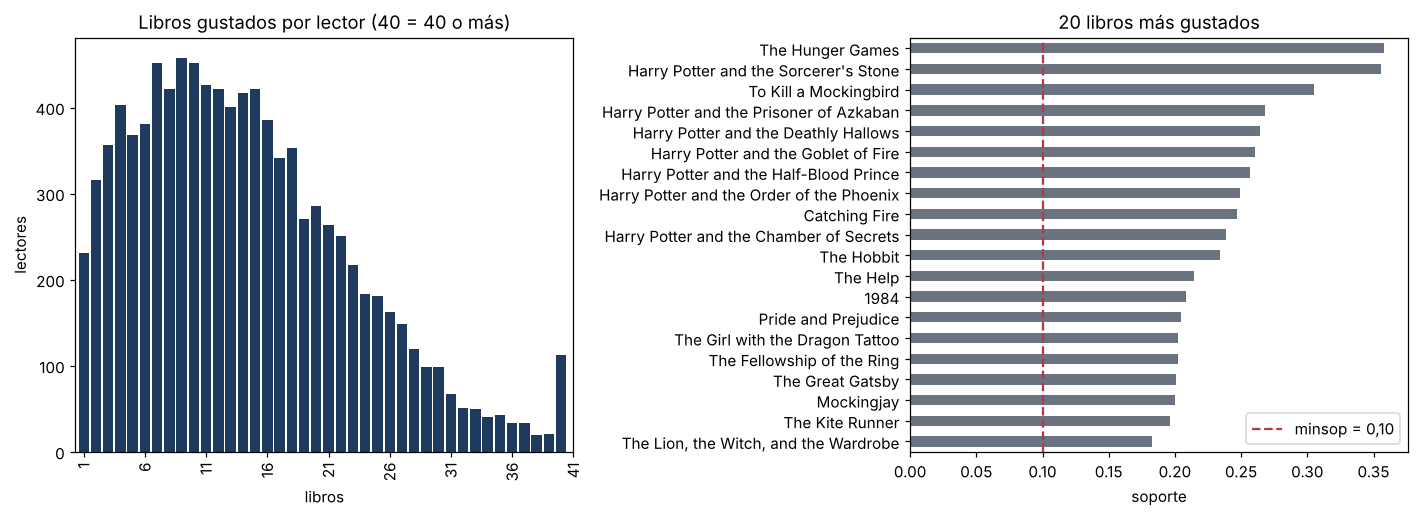

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))

# Izquierda: cuántos libros del catálogo le gustaron a cada lector (40 = 40 o más)
libros_por_lector.clip(upper=40).value_counts().sort_index().plot.bar(ax=ax[0], color=AZUL, width=0.85)
ax[0].set_title("Libros gustados por lector (40 = 40 o más)")
ax[0].set_xlabel("libros")
ax[0].set_ylabel("lectores")
ax[0].set_xticks(range(0, 41, 5), range(1, 42, 5))

# Derecha: los 20 libros más gustados (cola larga)
soporte_libro.head(20).sort_values().plot.barh(ax=ax[1], color=GRIS)
ax[1].axvline(0.10, color=ROJO, linestyle="--", label="minsop = 0,10")
ax[1].set_title("20 libros más gustados")
ax[1].set_xlabel("soporte")
ax[1].legend()

plt.tight_layout()
plt.show()

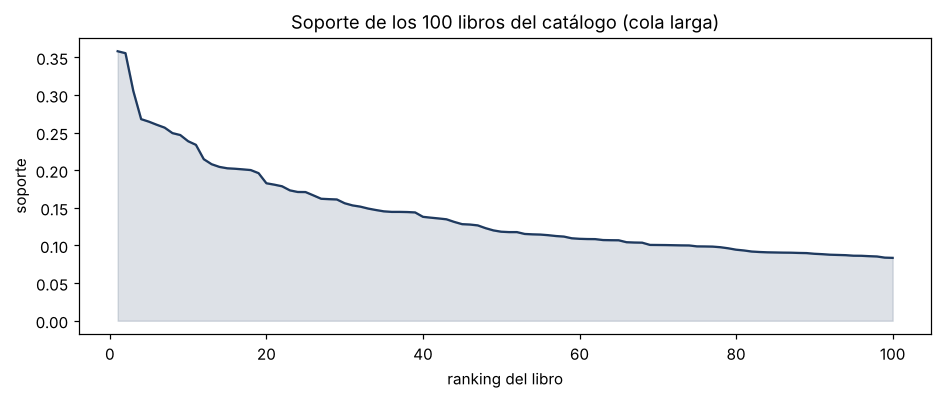

El libro más gustado aparece en 35.8% de los lectores; el n.º 100 en 8.4%


In [12]:
# Cola larga en todo el catálogo de 100 libros
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(range(1, len(soporte_libro) + 1), soporte_libro.values, color=AZUL)
ax.fill_between(range(1, len(soporte_libro) + 1), soporte_libro.values, color=AZUL, alpha=0.15)
ax.set_xlabel("ranking del libro")
ax.set_ylabel("soporte")
ax.set_title("Soporte de los 100 libros del catálogo (cola larga)")
plt.show()

print(f"El libro más gustado aparece en {soporte_libro.iloc[0]:.1%} de los lectores; el n.º 100 en {soporte_libro.iloc[-1]:.1%}")

**Co-ocurrencias.** $X^T X$ cuenta cuántos lectores comparten cada par de libros; la diagonal es el total de cada libro.

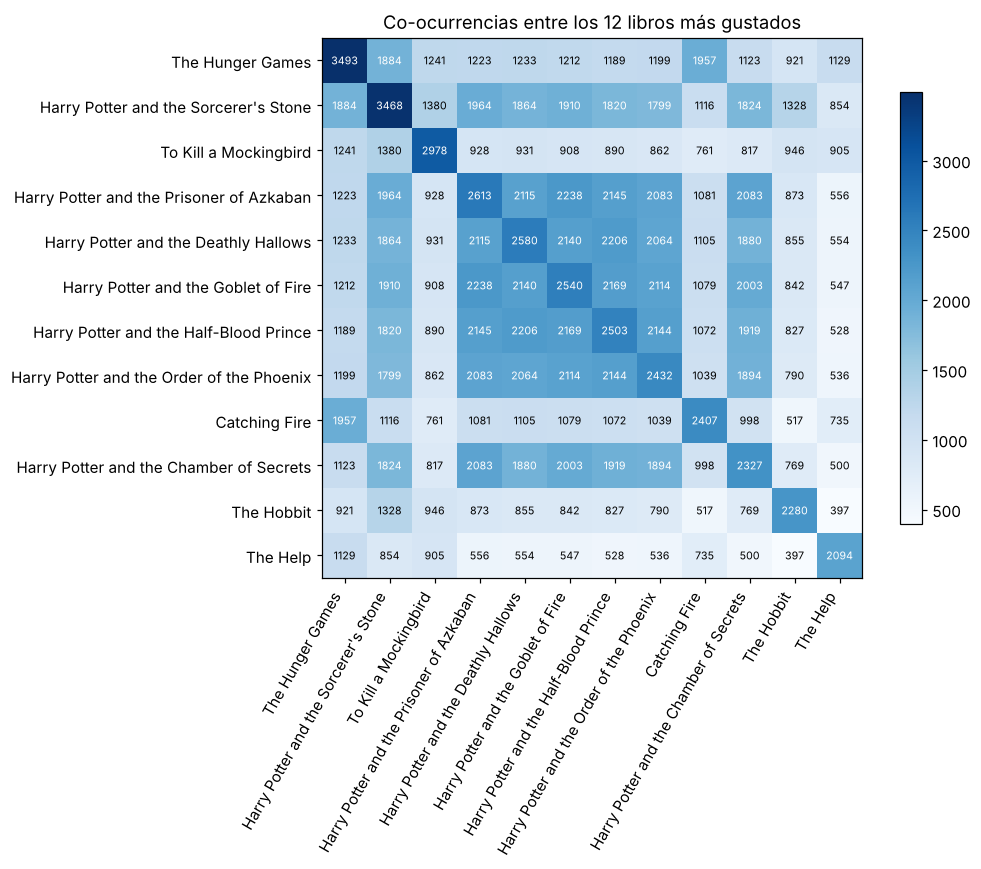

In [13]:
top12 = soporte_libro.head(12).index
sub = lectores[top12].astype(int)
coocurrencias = sub.T @ sub

fig, ax = plt.subplots(figsize=(10, 8))
imagen = ax.imshow(coocurrencias, cmap="Blues")
ax.set_xticks(range(12), top12, rotation=60, ha="right")
ax.set_yticks(range(12), top12)
limite = coocurrencias.values.max() / 2
for i in range(12):
    for j in range(12):
        valor = coocurrencias.iat[i, j]
        ax.text(j, i, valor, ha="center", va="center", fontsize=7,
                color="white" if valor > limite else "black")
ax.set_title("Co-ocurrencias entre los 12 libros más gustados")
plt.colorbar(imagen, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

**Hallazgos de la exploración (orientan los umbrales):**
1. **Matriz relativamente densa para un problema de canasta:** 14,2 % de celdas con 1 (Groceries tenía ≈ 2,6 %). Cada lector disfrutó en promedio **14,2 libros** del catálogo (mediana 13) y solo el 2,4 % tiene un único libro → hay mucha co-ocurrencia que analizar.
2. **Cola larga moderada:** el libro más gustado (*The Hunger Games*) aparece en el 35,8 % de los lectores y el n.º 100 en el 8,4 %. Como **todos** los libros superan el 8 %, un soporte mínimo bajo (≤ 0,05) generaría decenas de miles de reglas.
3. **Las sagas dominan las co-ocurrencias:** en la matriz de los 12 más gustados, los 7 libros de *Harry Potter* forman un bloque oscuro (entre 1.800 y 2.240 lectores comparten cada par), igual que *The Hunger Games* con *Catching Fire*. Esperamos muchas reglas "dentro de la misma saga".
4. **Consecuencia para los umbrales:** para describir asociaciones fuertes conviene un soporte alto (≈ 0,10, es decir, ≥ 975 lectores); para el recomendador conviene uno más bajo, para que también los libros menos populares puedan recomendarse.

## 4. Itemsets y reglas

### 4.1 Cálculo a mano de una regla y verificación con `mlxtend`

$$ sop = P(X \cap Z), \qquad conf = \frac{P(X \cap Z)}{P(X)}, \qquad lift = \frac{conf}{P(Z)} $$

Regla: **{The Hunger Games} ⇒ {Catching Fire}** (primer y segundo libro de la saga).

In [14]:
X, Z = "The Hunger Games", "Catching Fire"

n = len(lectores)
con_x = lectores[X].sum()
con_z = lectores[Z].sum()
con_ambos = (lectores[X] & lectores[Z]).sum()

soporte_mano = con_ambos / n
confianza_mano = con_ambos / con_x
lift_mano = confianza_mano / (con_z / n)

print(f"n = {n} | con X = {con_x} | con Z = {con_z} | con ambos = {con_ambos}")
print(f"soporte   = {con_ambos}/{n} = {soporte_mano:.3f}")
print(f"confianza = {con_ambos}/{con_x} = {confianza_mano:.3f}")
print(f"lift      = {confianza_mano:.3f} / {con_z / n:.3f} = {lift_mano:.3f}")

n = 9753 | con X = 3493 | con Z = 2407 | con ambos = 1957
soporte   = 1957/9753 = 0.201
confianza = 1957/3493 = 0.560
lift      = 0.560 / 0.247 = 2.270


In [15]:
# Verificación: la misma regla calculada por mlxtend
pares_verif = apriori(lectores[[X, Z]], min_support=0.01, use_colnames=True)
verif = association_rules(pares_verif, metric="confidence", min_threshold=0)
verif = verif[(verif["antecedents"] == frozenset({X})) & (verif["consequents"] == frozenset({Z}))]
display(tabla_reglas(verif))

assert np.isclose(verif["support"].iloc[0], soporte_mano)
assert np.isclose(verif["confidence"].iloc[0], confianza_mano)
assert np.isclose(verif["lift"].iloc[0], lift_mano)
print("✔ El cálculo a mano coincide con mlxtend")

,regla,soporte,confianza,lift,leverage,conviccion
0,{The Hunger Games} ⇒ {Catching Fire},0.201,0.560,2.270,0.112,1.713


✔ El cálculo a mano coincide con mlxtend


**Lectura:** el 20,1 % de los lectores disfrutó ambos libros. De quienes disfrutaron *The Hunger Games*,
el 56,0 % también disfrutó *Catching Fire*, y eso es **2,27 veces** más que lo esperado si los gustos fueran independientes.

### 4.2 Sensibilidad de umbrales
Número de itemsets frecuentes y de reglas para 4 valores de `min_support` y 3 de confianza mínima.

In [16]:
filas = []
for soporte in [0.05, 0.08, 0.10, 0.15]:
    frecuentes = fpgrowth(lectores, min_support=soporte, use_colnames=True)
    fila = {"min_support": soporte,
            "itemsets": len(frecuentes),
            "tamaño máx.": frecuentes["itemsets"].apply(len).max()}
    for confianza in [0.5, 0.6, 0.7]:
        fila[f"reglas conf≥{confianza}"] = len(association_rules(frecuentes, metric="confidence",
                                                                 min_threshold=confianza))
    filas.append(fila)

sensibilidad = pd.DataFrame(filas)
sensibilidad

,min_support,itemsets,tamaño máx.,reglas conf≥0.5,reglas conf≥0.6,reglas conf≥0.7
0,0.050,1996,9,30738,26925,21169
1,0.080,510,7,3980,3572,3123
2,0.100,256,7,1996,1836,1517
3,0.150,132,6,963,926,777


**Elección de umbrales para la descripción de reglas: `min_support = 0,10` y `min_confidence = 0,60`.**
- Con soporte 0,05 aparecen **≈ 27.000 reglas** (conf ≥ 0,6): imposible de interpretar y con itemsets de hasta 9 libros.
- Con 0,10 quedan **1.836 reglas**: un tamaño manejable, y cada regla está respaldada por **al menos 975 lectores** (10 % de 9.753).
- Confianza 0,60: la regla acierta en la mayoría de los casos; subir a 0,70 elimina 319 reglas más sin cambiar el panorama.
- En la sección 6 usamos umbrales **más bajos** para el recomendador, porque ahí el objetivo es la cobertura, no la descripción.

In [17]:
MIN_SOPORTE = 0.10
MIN_CONFIANZA = 0.60

### 4.3 Apriori vs. FP-Growth
Deben encontrar **exactamente los mismos itemsets**; cambia solo la forma de buscarlos (y el tiempo).

In [18]:
tiempos = {}

inicio = time.perf_counter()
items_apriori = apriori(lectores, min_support=MIN_SOPORTE, use_colnames=True)
tiempos["Apriori"] = time.perf_counter() - inicio

inicio = time.perf_counter()
items_fp = fpgrowth(lectores, min_support=MIN_SOPORTE, use_colnames=True)
tiempos["FP-Growth"] = time.perf_counter() - inicio

# Comparamos los conjuntos de itemsets y sus soportes
a = items_apriori.set_index("itemsets")["support"]
b = items_fp.set_index("itemsets")["support"]
mismos = set(a.index) == set(b.index) and np.allclose(a.sort_index(key=lambda s: s.map(texto_itemset)),
                                                      b.sort_index(key=lambda s: s.map(texto_itemset)))
print(f"Itemsets Apriori: {len(a)} | FP-Growth: {len(b)} | ¿idénticos? {mismos}")

# Repetimos 3 veces para medir el tiempo con menos ruido
for nombre, algoritmo in [("Apriori", apriori), ("FP-Growth", fpgrowth)]:
    medidas = []
    for _ in range(3):
        inicio = time.perf_counter()
        algoritmo(lectores, min_support=MIN_SOPORTE, use_colnames=True)
        medidas.append(time.perf_counter() - inicio)
    tiempos[nombre] = np.median(medidas)

pd.DataFrame({"tiempo (s)": tiempos})

Itemsets Apriori: 256 | FP-Growth: 256 | ¿idénticos? True


,tiempo (s)
Apriori,0.047
FP-Growth,0.513


In [19]:
# Tiempo según el soporte mínimo: la diferencia crece cuando el soporte baja
filas = []
for soporte in [0.15, 0.10, 0.08, 0.06]:
    fila = {"min_support": soporte}
    for nombre, algoritmo in [("Apriori", apriori), ("FP-Growth", fpgrowth)]:
        inicio = time.perf_counter()
        resultado = algoritmo(lectores, min_support=soporte, use_colnames=True)
        fila[f"{nombre} (s)"] = time.perf_counter() - inicio
    fila["itemsets"] = len(resultado)
    filas.append(fila)
tiempos_soporte = pd.DataFrame(filas)
tiempos_soporte

,min_support,Apriori (s),FP-Growth (s),itemsets
0,0.150,0.013,0.130,132
1,0.100,0.046,0.561,256
2,0.080,0.086,0.645,510
3,0.060,0.108,0.542,1194


**Resultado:** ambos algoritmos encuentran **exactamente los mismos 256 itemsets** con los mismos soportes.
En esta base **Apriori es más rápido**, a diferencia de Groceries: con solo **100 ítems** y una matriz relativamente
densa, Apriori genera pocos candidatos y los cuenta con operaciones vectorizadas de numpy, mientras que FP-Growth
paga el costo fijo de construir el árbol FP en Python. FP-Growth gana cuando hay **muchos ítems y soportes muy bajos**
(miles de candidatos), que no es nuestro caso por haber reducido el catálogo a 100 libros.

### 4.4 Tabla de reglas (soporte, confianza, lift, leverage y convicción)
- **Leverage** $= P(X \cap Z) - P(X)P(Z)$: exceso de co-ocurrencia sobre lo esperado.
- **Convicción** $= \dfrac{1 - P(Z)}{1 - conf}$: cuántas veces más fallaría la regla si $X$ y $Z$ fueran independientes.

In [20]:
itemsets = items_fp.copy()
itemsets["tamaño"] = itemsets["itemsets"].apply(len)
print("Itemsets frecuentes por tamaño:")
print(itemsets.groupby("tamaño")["itemsets"].count().to_string())

reglas = association_rules(items_fp, metric="confidence", min_threshold=MIN_CONFIANZA)
print(f"\nReglas (minsop = {MIN_SOPORTE}, minconf = {MIN_CONFIANZA}): {len(reglas)}")
tabla_reglas(reglas).head(15)

Itemsets frecuentes por tamaño:
tamaño
1    74
2    55
3    56
4    42
5    21
6     7
7     1

Reglas (minsop = 0.1, minconf = 0.6): 1836


,regla,soporte,confianza,lift,leverage,conviccion
0,"{Harry Potter and the Chamber of Secrets, Harry Potter and the Goblet of Fir...",0.133,0.721,4.694,0.105,3.029
1,"{Harry Potter and the Deathly Hallows, Harry Potter and the Order of the Pho...",0.133,0.870,4.694,0.105,6.255
2,"{Harry Potter and the Chamber of Secrets, Harry Potter and the Deathly Hallo...",0.133,0.763,4.681,0.105,3.534
3,"{Harry Potter and the Goblet of Fire, Harry Potter and the Half-Blood Prince...",0.133,0.819,4.681,0.105,4.555
4,"{Harry Potter and the Chamber of Secrets, Harry Potter and the Deathly Hallo...",0.133,0.737,4.675,0.105,3.206
5,"{Harry Potter and the Half-Blood Prince, Harry Potter and the Order of the P...",0.133,0.847,4.675,0.105,5.337
6,{A Clash of Kings} ⇒ {A Game of Thrones},0.102,0.830,4.644,0.080,4.831
7,"{Harry Potter and the Chamber of Secrets, Harry Potter and the Deathly Hallo...",0.133,0.795,4.642,0.105,4.049
8,"{Harry Potter and the Half-Blood Prince, Harry Potter and the Prisoner of Az...",0.133,0.779,4.642,0.105,3.768
9,"{Harry Potter and the Deathly Hallows, Harry Potter and the Goblet of Fire, ...",0.133,0.731,4.620,0.105,3.134


In [21]:
# ¿Son todas reglas "dentro de una saga"? Las reglas que mezclan sagas o autores distintos son las más interesantes
autor_de = libros.drop_duplicates("libro").set_index("libro")["autor"]

def autores(itemset):
    return {autor_de[l] for l in itemset}

reglas["mismo_autor"] = [autores(x | z).__len__() == 1 for x, z in zip(reglas["antecedents"], reglas["consequents"])]
print(f"Reglas con todos los libros del mismo autor: {reglas['mismo_autor'].mean():.1%}")

print("\nReglas simples (1 ⇒ 1) entre autores DISTINTOS, ordenadas por lift:")
simples = reglas[(reglas["antecedents"].apply(len) == 1) & ~reglas["mismo_autor"]]
tabla_reglas(simples).head(10)

Reglas con todos los libros del mismo autor: 95.8%

Reglas simples (1 ⇒ 1) entre autores DISTINTOS, ordenadas por lift:


,regla,soporte,confianza,lift,leverage,conviccion
0,{Divergent} ⇒ {The Hunger Games},0.112,0.671,1.875,0.052,1.953
1,{The Fellowship of the Ring} ⇒ {Harry Potter and the Sorcerer's Stone},0.122,0.603,1.696,0.050,1.623


**Interpretación de 5 reglas en el lenguaje de una biblioteca:**

1. **{The Hunger Games} ⇒ {Catching Fire}** (sop 0,201 · conf 0,56 · lift 2,27). De cada 100 lectores que disfrutaron el primer libro, 56 también disfrutaron el segundo: **2,3 veces** más de lo esperado. *Acción:* al devolver el libro 1, ofrecer el préstamo del libro 2.
2. **{Harry Potter: Chamber of Secrets, Goblet of Fire, …} ⇒ {otro Harry Potter}** (lift ≈ 4,7, conf 0,72–0,88). Es la regla de lift más alto: quien disfrutó varios libros de la saga casi seguro disfruta el resto. Es **cierta pero obvia** (la saga se lee en orden); su valor es asegurar disponibilidad de ejemplares, no descubrir algo nuevo.
3. **{A Clash of Kings} ⇒ {A Game of Thrones}** (sop 0,102 · conf 0,83 · lift 4,64 · convicción 4,8). El 83 % de quienes disfrutaron el libro 2 también disfrutaron el libro 1. La dirección "2 ⇒ 1" muestra que la regla describe **gusto compartido**, no orden de lectura.
4. **{Divergent} ⇒ {The Hunger Games}** (sop 0,112 · conf 0,67 · lift 1,88). Primera regla entre **autores distintos**: lectores de distopía juvenil. *Acción:* una estantería o lista temática "distopías juveniles".
5. **{The Fellowship of the Ring} ⇒ {Harry Potter and the Sorcerer's Stone}** (sop 0,122 · conf 0,60 · lift 1,70). Puente entre las dos grandes sagas de fantasía: el 60 % de quienes disfrutaron Tolkien también disfrutó Harry Potter.

**Hallazgo clave:** el **95,8 %** de las reglas tiene todos sus libros del **mismo autor**. Con umbrales altos las reglas confirman lo evidente (sagas); las reglas "útiles para descubrir" aparecen con lift moderado (1,7–1,9) y por eso el recomendador usa umbrales más bajos.

### 4.5 ¿Por qué no basta la confianza?
*The Hunger Games* le gustó a 1 de cada 3 lectores. Cualquier regla $X ⇒$ {The Hunger Games} tendrá una confianza
"razonable" aunque no exista asociación. Buscamos reglas con **confianza alta y lift ≈ 1**.

In [22]:
def evaluar_regla(antecedente, consecuente):
    # Soporte, confianza, P(consecuente) y lift de una regla simple {antecedente} ⇒ {consecuente}
    tiene_x = lectores[antecedente]
    tiene_z = lectores[consecuente]
    p_x, p_z = tiene_x.mean(), tiene_z.mean()
    p_xz = (tiene_x & tiene_z).mean()
    return {"regla": f"{{{antecedente}}} ⇒ {{{consecuente}}}",
            "soporte": p_xz, "confianza": p_xz / p_x, "P(Z)": p_z, "lift": p_xz / p_x / p_z}

# Todas las reglas simples hacia los 2 libros más gustados, con soporte del antecedente suficiente
candidatas = pd.DataFrame([evaluar_regla(x, z)
                           for z in soporte_libro.index[:2]
                           for x in soporte_libro.index if x != z])
lift_uno = candidatas[candidatas["lift"].between(0.95, 1.05)].sort_values("confianza", ascending=False)
lift_uno.head(5)

,regla,soporte,confianza,P(Z),lift
69,{The Alchemist} ⇒ {The Hunger Games},0.038,0.375,0.358,1.047
28,{Lord of the Flies} ⇒ {The Hunger Games},0.059,0.375,0.358,1.047
193,{The Poisonwood Bible} ⇒ {Harry Potter and the Sorcerer's Stone},0.032,0.373,0.356,1.049
64,{The Secret Garden} ⇒ {The Hunger Games},0.039,0.372,0.358,1.040
195,{The Pillars of the Earth} ⇒ {Harry Potter and the Sorcerer's Stone},0.032,0.372,0.356,1.047


In [23]:
# Comparación: confianzas del mismo orden, lifts muy distintos
comparacion = pd.DataFrame([
    evaluar_regla(lift_uno.iloc[0]["regla"].split("} ⇒ {")[0][1:], lift_uno.iloc[0]["regla"].split("} ⇒ {")[1][:-1]),
    evaluar_regla("The Hunger Games", "Catching Fire"),
    evaluar_regla("Harry Potter and the Sorcerer's Stone", "Harry Potter and the Chamber of Secrets"),
])
comparacion

,regla,soporte,confianza,P(Z),lift
0,{The Alchemist} ⇒ {The Hunger Games},0.038,0.375,0.358,1.047
1,{The Hunger Games} ⇒ {Catching Fire},0.201,0.560,0.247,2.270
2,{Harry Potter and the Sorcerer's Stone} ⇒ {Harry Potter and the Chamber of S...,0.187,0.526,0.239,2.204


**Explicación con $P(Z)$:** *{The Alchemist} ⇒ {The Hunger Games}* tiene confianza **0,375**, que parece razonable,
pero $P(\text{The Hunger Games}) = 0{,}358$: **un lector cualquiera** ya tiene 35,8 % de probabilidad de disfrutarlo.
El lift $0{,}375 / 0{,}358 = 1{,}05 ≈ 1$ indica que saber que le gustó *The Alchemist* **no cambia** la probabilidad:
la regla solo refleja que *The Hunger Games* es muy popular. En cambio, *{The Hunger Games} ⇒ {Catching Fire}* tiene
una confianza parecida (0,56) pero lift 2,27, porque *Catching Fire* es menos común ($P(Z) = 0{,}247$).
**No usaríamos** la primera regla: recomendaría lo mismo que recomendar "lo más popular".

## 5. Fisher, redundantes y consulta dirigida

### 5.1 Significancia: test exacto de Fisher con corrección de Holm

|  | Tiene Z | No tiene Z |
|---|---|---|
| **Tiene X** | a | b |
| **No tiene X** | c | d |

Test **unilateral** (`alternative="greater"`): ¿tener X aumenta la probabilidad de Z?
Como probamos muchas reglas a la vez, corregimos con **Holm** (controla la probabilidad de al menos un falso positivo).

In [24]:
def p_valor_fisher(antecedente, consecuente, datos=lectores):
    tiene_x = datos[list(antecedente)].all(axis=1)
    tiene_z = datos[list(consecuente)].all(axis=1)
    a = (tiene_x & tiene_z).sum()
    b = (tiene_x & ~tiene_z).sum()
    c = (~tiene_x & tiene_z).sum()
    d = (~tiene_x & ~tiene_z).sum()
    _, p = fisher_exact([[a, b], [c, d]], alternative="greater")
    return p


reglas["p_valor"] = [p_valor_fisher(x, z) for x, z in zip(reglas["antecedents"], reglas["consequents"])]
reglas["significativa"], reglas["p_ajustado"], _, _ = multipletests(reglas["p_valor"], alpha=0.05, method="holm")

print(f"Reglas significativas (Holm, α = 0,05): {reglas['significativa'].sum()} de {len(reglas)}")

Reglas significativas (Holm, α = 0,05): 1836 de 1836


In [25]:
# ¿Sobreviven todas? Para ver el efecto, aplicamos Fisher a reglas débiles (lift cercano a 1) con umbrales bajos
items_bajos = fpgrowth(lectores, min_support=0.05, use_colnames=True, max_len=2)
reglas_debiles = association_rules(items_bajos, metric="confidence", min_threshold=0.2)
reglas_debiles = reglas_debiles[reglas_debiles["lift"] < 1.2].copy()
reglas_debiles["p_valor"] = [p_valor_fisher(x, z) for x, z in zip(reglas_debiles["antecedents"], reglas_debiles["consequents"])]
reglas_debiles["significativa"], reglas_debiles["p_ajustado"], _, _ = multipletests(reglas_debiles["p_valor"], method="holm")

print(f"Reglas simples con lift < 1,2: {len(reglas_debiles)} | significativas tras Holm: {reglas_debiles['significativa'].sum()}")
display(tabla_reglas(reglas_debiles[~reglas_debiles["significativa"]]).head(5))

Reglas simples con lift < 1,2: 135 | significativas tras Holm: 72


,regla,soporte,confianza,lift,leverage,conviccion
0,{Animal Farm} ⇒ {Harry Potter and the Order of the Phoenix},0.050,0.278,1.116,0.005,1.040
1,{Harry Potter and the Order of the Phoenix} ⇒ {Animal Farm},0.050,0.202,1.116,0.005,1.026
2,{The Kite Runner} ⇒ {The Hobbit},0.051,0.260,1.114,0.005,1.036
3,{The Hobbit} ⇒ {The Kite Runner},0.051,0.218,1.114,0.005,1.029
4,{1984} ⇒ {Harry Potter and the Chamber of Secrets},0.055,0.266,1.113,0.006,1.037


**Resultado:** las **1.836 reglas** (minsop 0,10) sobreviven a Holm. Con ≥ 975 lectores por regla y lift ≥ 1,4,
la evidencia es abrumadora (p-valores prácticamente 0). Fisher sí filtra cuando miramos reglas **débiles**:
de 135 reglas simples con lift < 1,2, **63 no son significativas** tras Holm (por ejemplo,
*{Animal Farm} ⇒ {HP Order of the Phoenix}*, lift 1,12): su exceso de co-ocurrencia puede ser azar.
Lección: con muestras grandes la significancia es fácil de alcanzar; **el lift es el filtro que más discrimina**.
En el recomendador (umbrales más bajos), Fisher descarta 89 de 6.123 reglas (sección 9).

### 5.2 Reglas redundantes
$X ⇒ Z$ es redundante si existe $X' ⊂ X$ con $X' ⇒ Z$ y **confianza igual o mayor**.

In [26]:
def marcar_redundantes(reglas):
    # Para cada regla buscamos otra con el mismo consecuente, antecedente más chico y confianza ≥
    redundante = []
    for _, regla in reglas.iterrows():
        mismas_z = reglas[reglas["consequents"] == regla["consequents"]]
        mas_simples = mismas_z[mismas_z["antecedents"].apply(lambda x: x < regla["antecedents"])]
        redundante.append((mas_simples["confidence"] >= regla["confidence"]).any())
    return np.array(redundante)


reglas["redundante"] = marcar_redundantes(reglas)
print(f"Reglas redundantes: {reglas['redundante'].sum()} de {len(reglas)} ({reglas['redundante'].mean():.1%})")

ejemplo = reglas[reglas["redundante"]].sort_values("lift", ascending=False).iloc[0]
mas_simple = reglas[(reglas["consequents"] == ejemplo["consequents"]) &
                    (reglas["antecedents"].apply(lambda x: x < ejemplo["antecedents"]))].sort_values("confidence").iloc[-1]
print(f"\nRedundante: {texto_itemset(ejemplo['antecedents'])} ⇒ {texto_itemset(ejemplo['consequents'])}  (conf = {ejemplo['confidence']:.3f})")
print(f"Más simple: {texto_itemset(mas_simple['antecedents'])} ⇒ {texto_itemset(mas_simple['consequents'])}  (conf = {mas_simple['confidence']:.3f})")

Reglas redundantes: 2 de 1836 (0.1%)

Redundante: {Harry Potter and the Deathly Hallows, Harry Potter and the Order of the Phoenix, The Hunger Games} ⇒ {Harry Potter and the Half-Blood Prince}  (conf = 0.945)
Más simple: {Harry Potter and the Deathly Hallows, Harry Potter and the Order of the Phoenix} ⇒ {Harry Potter and the Half-Blood Prince}  (conf = 0.946)


In [27]:
# Reglas finales: significativas y no redundantes
reglas_finales = reglas[reglas["significativa"] & ~reglas["redundante"]].copy()
print(f"Reglas iniciales: {len(reglas)} → significativas: {reglas['significativa'].sum()} → "
      f"significativas y no redundantes: {len(reglas_finales)}")
tabla_reglas(reglas_finales).head(10)

Reglas iniciales: 1836 → significativas: 1836 → significativas y no redundantes: 1834


,regla,soporte,confianza,lift,leverage,conviccion
0,"{Harry Potter and the Chamber of Secrets, Harry Potter and the Goblet of Fir...",0.133,0.721,4.694,0.105,3.029
1,"{Harry Potter and the Deathly Hallows, Harry Potter and the Order of the Pho...",0.133,0.870,4.694,0.105,6.255
2,"{Harry Potter and the Goblet of Fire, Harry Potter and the Half-Blood Prince...",0.133,0.819,4.681,0.105,4.555
3,"{Harry Potter and the Chamber of Secrets, Harry Potter and the Deathly Hallo...",0.133,0.763,4.681,0.105,3.534
4,"{Harry Potter and the Chamber of Secrets, Harry Potter and the Deathly Hallo...",0.133,0.737,4.675,0.105,3.206
5,"{Harry Potter and the Half-Blood Prince, Harry Potter and the Order of the P...",0.133,0.847,4.675,0.105,5.337
6,{A Clash of Kings} ⇒ {A Game of Thrones},0.102,0.830,4.644,0.080,4.831
7,"{Harry Potter and the Chamber of Secrets, Harry Potter and the Deathly Hallo...",0.133,0.795,4.642,0.105,4.049
8,"{Harry Potter and the Half-Blood Prince, Harry Potter and the Prisoner of Az...",0.133,0.779,4.642,0.105,3.768
9,"{Harry Potter and the Deathly Hallows, Harry Potter and the Goblet of Fire, ...",0.133,0.731,4.620,0.105,3.134


### 5.3 Consulta dirigida: ¿qué lleva a disfrutar *The Hobbit*?
Una biblioteca quiere impulsar préstamos de *The Hobbit* (clásico de fantasía con muchas ediciones disponibles).
Fijamos el consecuente y vemos qué libros lo anticipan.

In [28]:
OBJETIVO = "The Hobbit"
items_consulta = fpgrowth(lectores, min_support=0.05, use_colnames=True, max_len=3)
reglas_consulta = association_rules(items_consulta, metric="confidence", min_threshold=0.4)
reglas_consulta = reglas_consulta[reglas_consulta["consequents"] == frozenset({OBJETIVO})]
print(f"Reglas con consecuente {{{OBJETIVO}}}: {len(reglas_consulta)}  (P(Z) = {soporte_libro[OBJETIVO]:.3f})")
tabla_reglas(reglas_consulta).head(8)

Reglas con consecuente {The Hobbit}: 27  (P(Z) = 0.234)


,regla,soporte,confianza,lift,leverage,conviccion
0,"{1984, The Fellowship of the Ring} ⇒ {The Hobbit}",0.056,0.785,3.359,0.039,3.569
1,"{Harry Potter and the Prisoner of Azkaban, The Fellowship of the Ring} ⇒ {Th...",0.056,0.749,3.204,0.039,3.052
2,"{Harry Potter and the Goblet of Fire, The Fellowship of the Ring} ⇒ {The Hob...",0.054,0.742,3.173,0.037,2.968
3,"{The Fellowship of the Ring, The Lion, the Witch, and the Wardrobe} ⇒ {The H...",0.054,0.738,3.158,0.037,2.926
4,"{Harry Potter and the Sorcerer's Stone, The Fellowship of the Ring} ⇒ {The H...",0.090,0.736,3.147,0.061,2.899
5,"{The Fellowship of the Ring, The Return of the King} ⇒ {The Hobbit}",0.059,0.735,3.144,0.040,2.890
6,"{A Game of Thrones, The Fellowship of the Ring} ⇒ {The Hobbit}",0.053,0.732,3.132,0.036,2.861
7,"{Harry Potter and the Deathly Hallows, The Fellowship of the Ring} ⇒ {The Ho...",0.055,0.731,3.128,0.038,2.852


**Lectura:** el mejor anticipador de *The Hobbit* es haber disfrutado **The Fellowship of the Ring**, que aparece en las 8 mejores reglas.
Por ejemplo, de quienes disfrutaron *1984* y *Fellowship*, el 78,5 % disfrutó *The Hobbit* (lift 3,36, frente a $P(Z)$ = 0,234).
*Acción:* promocionar *The Hobbit* entre lectores con préstamos de *El Señor de los Anillos*, aunque aún no lo hayan pedido,
y combinarlo con otros perfiles (*1984*, *Narnia*, *Game of Thrones*) para llegar a lectores de fantasía en general.

### 5.4 Visualización de reglas

In [29]:
def color_lift(valor, minimo, maximo):
    escala = plt.get_cmap("Reds")
    proporcion = (valor - minimo) / (maximo - minimo) if maximo > minimo else 1
    return mcolors.to_hex(escala(0.25 + 0.75 * proporcion))


def mostrar_red(red, alto=650):
    # pyvis genera una página HTML; la mostramos dentro de un iframe para que funcione en Colab
    pagina = red.generate_html()
    display(HTML(f'<iframe srcdoc="{html.escape(pagina)}" width="100%" height="{alto + 20}" '
                 f'style="border:1px solid #ddd; border-radius:6px"></iframe>'))

**a) Dispersión interactiva soporte–confianza coloreada por lift (Plotly).**

In [30]:
dispersion = tabla_reglas(reglas)
figura = px.scatter(dispersion, x="soporte", y="confianza", color="lift",
                    hover_name="regla", hover_data={"soporte": ":.3f", "confianza": ":.3f", "lift": ":.2f"},
                    color_continuous_scale="Reds", height=500,
                    title=f"{len(dispersion)} reglas (minsop = {MIN_SOPORTE}; minconf = {MIN_CONFIANZA})")
figura.update_traces(marker=dict(size=7, line=dict(width=0.3, color="white")))
figura.show()

**b) Grafo de reglas (pyvis)**: las 25 reglas finales de mayor lift. Cuadros = libros; círculos = reglas (tamaño = soporte, color = lift).

In [31]:
def grafo_reglas(reglas, alto=650):
    red = Network(height=f"{alto}px", width="100%", directed=True, cdn_resources="remote")
    lift_min, lift_max = reglas["lift"].min(), reglas["lift"].max()
    soporte_max = reglas["support"].max()
    for i, regla in reglas.reset_index(drop=True).iterrows():
        nombre = f"regla {i + 1}"
        detalle = (f"{texto_itemset(regla['antecedents'])} ⇒ {texto_itemset(regla['consequents'])}\n"
                   f"soporte:   {regla['support']:.3f}\nconfianza: {regla['confidence']:.3f}\nlift:      {regla['lift']:.2f}")
        red.add_node(nombre, label=" ", title=detalle, shape="dot",
                     size=10 + 25 * regla["support"] / soporte_max,
                     color=color_lift(regla["lift"], lift_min, lift_max))
        for libro in regla["antecedents"] | regla["consequents"]:
            red.add_node(libro, label=libro, shape="box", color="#e6e9ef",
                         font={"color": AZUL, "size": 16}, title=f"soporte: {soporte_libro[libro]:.3f}")
        for libro in regla["antecedents"]:
            red.add_edge(libro, nombre, color=GRIS)
        for libro in regla["consequents"]:
            red.add_edge(nombre, libro, color=GRIS)
    red.repulsion(node_distance=150, spring_length=120)
    return red


mostrar_red(grafo_reglas(reglas_finales.sort_values("lift", ascending=False).head(25)))

**c) Mapa de flujo libro → libro**: grosor = confianza, color = lift, tamaño del nodo = soporte.

In [32]:
pares = fpgrowth(lectores, min_support=0.05, use_colnames=True, max_len=2)
reglas_pares = association_rules(pares, metric="confidence", min_threshold=0.3)
reglas_pares["desde"] = reglas_pares["antecedents"].apply(lambda x: next(iter(x)))
reglas_pares["hacia"] = reglas_pares["consequents"].apply(lambda x: next(iter(x)))
reglas_pares = reglas_pares[reglas_pares["lift"] > 1.2].reset_index(drop=True)
print(f"Reglas libro → libro: {len(reglas_pares)} entre {reglas_pares['desde'].nunique()} libros")


def mapa_flujo(reglas_pares, lift_minimo=2.5, alto=700):
    seleccion = reglas_pares[reglas_pares["lift"] >= lift_minimo]
    red = Network(height=f"{alto}px", width="100%", directed=True, cdn_resources="remote")
    lift_min, lift_max = seleccion["lift"].min(), seleccion["lift"].max()
    for libro in set(seleccion["desde"]) | set(seleccion["hacia"]):
        red.add_node(libro, label=libro, shape="dot", color=AZUL, size=10 + 60 * soporte_libro[libro],
                     font={"size": 22, "color": AZUL, "strokeWidth": 5, "strokeColor": "white"},
                     title=f"{libro}\nsoporte: {soporte_libro[libro]:.3f}")
    for _, r in seleccion.iterrows():
        red.add_edge(r["desde"], r["hacia"], width=1 + 8 * r["confidence"],
                     color=color_lift(r["lift"], lift_min, lift_max),
                     title=f"{r['desde']} ⇒ {r['hacia']}\nconfianza: {r['confidence']:.3f}\nlift: {r['lift']:.2f}")
    red.barnes_hut(gravity=-9000, spring_length=160)
    print(f"Mostrando {len(seleccion)} reglas con lift ≥ {lift_minimo}")
    return red


mostrar_red(mapa_flujo(reglas_pares, lift_minimo=2.5))

Reglas libro → libro: 512 entre 74 libros
Mostrando 97 reglas con lift ≥ 2.5


**d) Cadena de lecturas: "este libro lleva a este, que lleva a este…"** (cadena de compras de la guía).
Partimos de un libro y seguimos, paso a paso, la regla más fuerte hacia un libro **nuevo**.
Criterio `"lift"` (asociación más fuerte) o `"confidence"` (más probable, tiende a los más gustados).

In [33]:
def cadena_de_compras(inicio, pasos=6, criterio="lift"):
    camino, tramos = [inicio], []
    while len(camino) < pasos:
        salidas = reglas_pares[(reglas_pares["desde"] == camino[-1]) & ~reglas_pares["hacia"].isin(camino)]
        if salidas.empty:
            break
        mejor = salidas.sort_values(criterio, ascending=False).iloc[0]
        tramos.append(mejor)
        camino.append(mejor["hacia"])
    # ¿El último libro vuelve a alguno anterior? (ciclo)
    regreso = reglas_pares[(reglas_pares["desde"] == camino[-1]) & reglas_pares["hacia"].isin(camino[:-1])]
    regreso = regreso.sort_values(criterio, ascending=False).head(1)
    tabla = pd.DataFrame({
        "paso": range(1, len(tramos) + 1),
        "regla": [f"{t['desde']} ⇒ {t['hacia']}" for t in tramos],
        "soporte": [t["support"] for t in tramos],
        "confianza": [t["confidence"] for t in tramos],
        "lift": [t["lift"] for t in tramos],
    })
    return camino, tabla, regreso


def mostrar_cadena(inicio, pasos=6, criterio="lift"):
    camino, tabla, regreso = cadena_de_compras(inicio, pasos, criterio)
    texto = " → ".join(camino)
    if not regreso.empty:
        texto += f"  ↺ vuelve a {regreso.iloc[0]['hacia']}"
    print(f"[{criterio}] {texto}")
    display(tabla)


mostrar_cadena("1984", criterio="lift")
mostrar_cadena("1984", criterio="confidence")

[lift] 1984 → Brave New World → Animal Farm → Lord of the Flies → Of Mice and Men → The Catcher in the Rye  ↺ vuelve a Lord of the Flies


,paso,regla,soporte,confianza,lift
0,1,1984 ⇒ Brave New World,0.075,0.363,3.021
1,2,Brave New World ⇒ Animal Farm,0.056,0.467,2.583
2,3,Animal Farm ⇒ Lord of the Flies,0.074,0.412,2.636
3,4,Lord of the Flies ⇒ Of Mice and Men,0.061,0.393,2.594
4,5,Of Mice and Men ⇒ The Catcher in the Rye,0.059,0.392,2.293


[confidence] 1984 → Animal Farm → To Kill a Mockingbird → Harry Potter and the Sorcerer's Stone → Harry Potter and the Prisoner of Azkaban → Harry Potter and the Goblet of Fire  ↺ vuelve a Harry Potter and the Prisoner of Azkaban


,paso,regla,soporte,confianza,lift
0,1,1984 ⇒ Animal Farm,0.106,0.510,2.818
1,2,Animal Farm ⇒ To Kill a Mockingbird,0.092,0.508,1.664
2,3,To Kill a Mockingbird ⇒ Harry Potter and the Sorcerer's Stone,0.141,0.463,1.303
3,4,Harry Potter and the Sorcerer's Stone ⇒ Harry Potter and the Prisoner of Azk...,0.201,0.566,2.114
4,5,Harry Potter and the Prisoner of Azkaban ⇒ Harry Potter and the Goblet of Fire,0.229,0.856,3.289


**Lectura (pregunta de la guía: ¿por qué el criterio de confianza termina en los más vendidos?).**
- Por **lift**, la cadena desde *1984* recorre **clásicos de lectura escolar**: *Brave New World → Animal Farm → Lord of the Flies → Of Mice and Men → The Catcher in the Rye* (lift 2,3–3,0 en cada paso) y vuelve a *Lord of the Flies* (ciclo).
- Por **confianza**, a los 3 pasos ya cae en **Harry Potter** (*To Kill a Mockingbird ⇒ HP Sorcerer's Stone*, lift 1,30). La confianza $P(Z|X)$ es alta cuando $Z$ es popular ($P(Z)$ grande), así que la cadena termina en los libros más gustados aunque la asociación sea débil.
- Conclusión: el lift mantiene la coherencia temática; la confianza arrastra hacia la popularidad (el mismo dilema precisión vs. novedad de la sección 7).

## 6. Recomendador basado en reglas

1. Tomamos los libros que le gustaron al lector.
2. **Activamos** las reglas cuyo antecedente está completo en esa lista.
3. Recomendamos consecuentes que **aún no ha leído**, ordenados por lift (o confianza).
4. Si ninguna regla se activa (**arranque en frío**), completamos con los más gustados.

**Umbrales del recomendador:** `minsop = 0,03`, `minconf = 0,30`, antecedentes de hasta 2 libros (`max_len = 3`).
Son más bajos que en la sección 4 porque el objetivo cambia: aquí queremos que **casi todo lector active alguna regla**
y que más libros del catálogo puedan ser recomendados (cobertura), no solo describir las reglas más fuertes.

In [34]:
REC_SOPORTE, REC_CONFIANZA, REC_MAX_LEN = 0.03, 0.30, 3


def minar_reglas(datos, soporte=REC_SOPORTE, confianza=REC_CONFIANZA, max_len=REC_MAX_LEN):
    # Mina reglas y deja solo las de un consecuente (más fáciles de recomendar)
    frecuentes = fpgrowth(datos, min_support=soporte, use_colnames=True, max_len=max_len)
    reglas = association_rules(frecuentes, metric="confidence", min_threshold=confianza)
    reglas = reglas[reglas["consequents"].apply(len) == 1].copy()
    reglas["producto"] = reglas["consequents"].apply(lambda z: next(iter(z)))
    return reglas.reset_index(drop=True)


reglas_rec = minar_reglas(lectores)
mas_gustados = soporte_libro.index.tolist()
print(f"Reglas disponibles para recomendar: {len(reglas_rec):,}")
print(f"Libros que aparecen como consecuente: {reglas_rec['producto'].nunique()} de {lectores.shape[1]}")

Reglas disponibles para recomendar: 6,123
Libros que aparecen como consecuente: 77 de 100


In [35]:
def recomendar(canasta, reglas, populares, top=3, orden="lift", lift_minimo=None):
    # lift_minimo=None → recomendador por reglas puro
    # lift_minimo=valor → híbrido conmutado: usa reglas solo si alguna activa supera ese lift
    canasta = set(canasta)

    # 1) Reglas activas: antecedente dentro de la canasta y libro aún no leído
    activa = reglas["antecedents"].apply(lambda x: x <= canasta)
    nueva = ~reglas["producto"].isin(canasta)
    candidatas = reglas[activa & nueva]

    # Híbrido conmutado: si ninguna regla activa es suficientemente fuerte, se descartan todas
    if lift_minimo is not None and (candidatas.empty or candidatas["lift"].max() < lift_minimo):
        candidatas = candidatas.iloc[0:0]

    # 2) Ordenamos y dejamos la mejor regla por libro
    candidatas = candidatas.sort_values([orden, "confidence"], ascending=False)
    candidatas = candidatas.drop_duplicates("producto").head(top)

    sugerencias = [{"libro": r["producto"],
                    "motivo": texto_itemset(r["antecedents"]) + " ⇒ " + texto_itemset(r["consequents"]),
                    "confianza": r["confidence"], "lift": r["lift"]}
                   for _, r in candidatas.iterrows()]

    # 3) Arranque en frío o faltan sugerencias: completamos con los más gustados no leídos
    ya = {s["libro"] for s in sugerencias}
    for libro in populares:
        if len(sugerencias) >= top:
            break
        if libro not in canasta and libro not in ya:
            sugerencias.append({"libro": libro, "motivo": "más gustado (respaldo)",
                                "confianza": np.nan, "lift": np.nan})
    return pd.DataFrame(sugerencias)

In [36]:
# Arranque en frío realista: un lector cuyo único libro favorito está FUERA del catálogo de 100
fuera_catalogo = (gustados[~gustados["book_id"].isin(catalogo)]["book_id"].value_counts().index[0])
libro_nuevo = libros.loc[libros["book_id"] == fuera_catalogo, "libro"].iloc[0]

ejemplos = {
    "Fan de fantasía":         ["The Hobbit", "The Fellowship of the Ring"],
    "Clásicos distópicos":     ["1984", "Animal Farm"],
    "Novela juvenil actual":   ["The Fault in Our Stars", "Looking for Alaska"],
    "Lector nuevo (frío)":     [libro_nuevo],
}

for nombre, canasta in ejemplos.items():
    print(f"\n▶ {nombre}: {canasta}")
    display(recomendar(canasta, reglas_rec, mas_gustados, top=5))


▶ Fan de fantasía: ['The Hobbit', 'The Fellowship of the Ring']


,libro,motivo,confianza,lift
0,The Return of the King,"{The Fellowship of the Ring, The Hobbit} ⇒ {The Return of the King}",0.426,3.973
1,The Two Towers,"{The Fellowship of the Ring, The Hobbit} ⇒ {The Two Towers}",0.428,3.942
2,The Hitchhiker's Guide to the Galaxy,"{The Fellowship of the Ring, The Hobbit} ⇒ {The Hitchhiker's Guide to the Ga...",0.331,2.285
3,"The Lion, the Witch, and the Wardrobe","{The Fellowship of the Ring, The Hobbit} ⇒ {The Lion, the Witch, and the War...",0.396,2.165
4,A Game of Thrones,"{The Fellowship of the Ring, The Hobbit} ⇒ {A Game of Thrones}",0.384,2.146



▶ Clásicos distópicos: ['1984', 'Animal Farm']


,libro,motivo,confianza,lift
0,Brave New World,"{1984, Animal Farm} ⇒ {Brave New World}",0.423,3.520
1,Lord of the Flies,"{1984, Animal Farm} ⇒ {Lord of the Flies}",0.477,3.053
2,Slaughterhouse-Five,"{1984, Animal Farm} ⇒ {Slaughterhouse-Five}",0.341,2.898
3,Fahrenheit 451,"{1984, Animal Farm} ⇒ {Fahrenheit 451}",0.395,2.881
4,The Catcher in the Rye,"{1984, Animal Farm} ⇒ {The Catcher in the Rye}",0.446,2.607



▶ Novela juvenil actual: ['The Fault in Our Stars', 'Looking for Alaska']


,libro,motivo,confianza,lift
0,Divergent,{The Fault in Our Stars} ⇒ {Divergent},0.413,2.481
1,Gone Girl,{The Fault in Our Stars} ⇒ {Gone Girl},0.331,2.047
2,The Book Thief,{The Fault in Our Stars} ⇒ {The Book Thief},0.314,1.948
3,Catching Fire,{The Fault in Our Stars} ⇒ {Catching Fire},0.418,1.695
4,Mockingjay,{The Fault in Our Stars} ⇒ {Mockingjay},0.334,1.670



▶ Lector nuevo (frío): ['Macbeth']


,libro,motivo,confianza,lift
0,The Hunger Games,más gustado (respaldo),NaN,NaN
1,Harry Potter and the Sorcerer's Stone,más gustado (respaldo),NaN,NaN
2,To Kill a Mockingbird,más gustado (respaldo),NaN,NaN
3,Harry Potter and the Prisoner of Azkaban,más gustado (respaldo),NaN,NaN
4,Harry Potter and the Deathly Hallows,más gustado (respaldo),NaN,NaN


**Lectura de las 4 canastas:**
- **Fan de fantasía:** recomienda los libros 2 y 3 de *El Señor de los Anillos* (lift ≈ 4) y luego fantasía de otros autores (*Narnia*, *Game of Thrones*). Cada sugerencia muestra la regla que la origina.
- **Clásicos distópicos:** *Brave New World* (lift 3,5), *Fahrenheit 451*, *Lord of the Flies*: coherente con el género.
- **Novela juvenil actual:** *Looking for Alaska* no activa reglas propias, pero *The Fault in Our Stars* sí (*Divergent*, *The Book Thief*…).
- **Lector nuevo (arranque en frío):** su único favorito (*Macbeth*) **no está en el catálogo de 100 libros**, así que ninguna regla se activa y el sistema cae al respaldo de **los más gustados**. Es la limitación clásica de las reglas: no pueden recomendar sin historial dentro del catálogo.

### 6.1 ¿Lift o confianza?

In [37]:
canasta = ["The Hunger Games", "Divergent"]
por_lift = recomendar(canasta, reglas_rec, mas_gustados, top=5, orden="lift")
por_conf = recomendar(canasta, reglas_rec, mas_gustados, top=5, orden="confidence")

comparacion = pd.DataFrame({
    "por lift": por_lift["libro"],
    "lift": por_lift["lift"].round(2),
    "por confianza": por_conf["libro"],
    "confianza": por_conf["confianza"].round(2),
    "soporte del libro (conf.)": por_conf["libro"].map(soporte_libro).round(3),
})
print(f"Canasta: {canasta}")
comparacion

Canasta: ['The Hunger Games', 'Divergent']


,por lift,lift,por confianza,confianza,soporte del libro (conf.)
0,Insurgent,4.990,Catching Fire,0.660,0.247
1,Mockingjay,2.670,Harry Potter and the Sorcerer's Stone,0.610,0.356
2,Catching Fire,2.660,Insurgent,0.540,0.109
3,The Fault in Our Stars,2.600,Mockingjay,0.530,0.200
4,Twilight,2.530,The Fault in Our Stars,0.440,0.171


**Lift vs. confianza:** ordenar por **confianza** pone arriba libros **muy populares** (*Catching Fire*, soporte 0,25;
*HP Sorcerer's Stone*, soporte 0,36), que el lector probablemente ya conoce. Ordenar por **lift** prioriza *Insurgent*
(lift 4,99, soporte 0,11): el siguiente libro de *Divergent*, mucho más específico para este lector.
La confianza favorece la **precisión** fácil; el lift, la **relevancia y la novedad**.

### 6.2 Híbrido conmutado
Usa reglas **solo si** alguna regla activa tiene lift > `lift_minimo`; si no, recomienda los más gustados.

In [38]:
for canasta in [["The Hobbit"], ["To Kill a Mockingbird"], [libro_nuevo]]:
    activas = reglas_rec[reglas_rec["antecedents"].apply(lambda x: x <= set(canasta)) & ~reglas_rec["producto"].isin(canasta)]
    lift_max = activas["lift"].max() if len(activas) else float("nan")
    print(f"\n▶ {canasta} → lift máximo de sus reglas activas: {lift_max:.2f}")
    display(recomendar(canasta, reglas_rec, mas_gustados, top=3, lift_minimo=2.0))


▶ ['The Hobbit'] → lift máximo de sus reglas activas: 2.91


,libro,motivo,confianza,lift
0,The Fellowship of the Ring,{The Hobbit} ⇒ {The Fellowship of the Ring},0.588,2.910
1,"The Lion, the Witch, and the Wardrobe","{The Hobbit} ⇒ {The Lion, the Witch, and the Wardrobe}",0.340,1.860
2,A Game of Thrones,{The Hobbit} ⇒ {A Game of Thrones},0.317,1.772



▶ ['To Kill a Mockingbird'] → lift máximo de sus reglas activas: 1.93


,libro,motivo,confianza,lift
0,The Hunger Games,más gustado (respaldo),NaN,NaN
1,Harry Potter and the Sorcerer's Stone,más gustado (respaldo),NaN,NaN
2,Harry Potter and the Prisoner of Azkaban,más gustado (respaldo),NaN,NaN



▶ ['Macbeth'] → lift máximo de sus reglas activas: nan


,libro,motivo,confianza,lift
0,The Hunger Games,más gustado (respaldo),NaN,NaN
1,Harry Potter and the Sorcerer's Stone,más gustado (respaldo),NaN,NaN
2,To Kill a Mockingbird,más gustado (respaldo),NaN,NaN


## 7. Evaluación offline (leave-one-out)

1. Partición **80 / 20** de los lectores con semilla 42. Las reglas se minan **solo** con entrenamiento.
2. A cada lector de prueba con ≥ 2 libros se le **oculta uno al azar**.
3. Se recomienda con el resto y se mide si el libro oculto aparece en los $N$ sugeridos: **HitRate@N**.
4. Se compara: reglas por lift, reglas por confianza, híbrido y la línea base de los más gustados.

In [39]:
generador = np.random.default_rng(SEMILLA)
orden_aleatorio = generador.permutation(len(lectores))
corte = int(0.8 * len(lectores))

entrenamiento = lectores.iloc[orden_aleatorio[:corte]]
prueba = lectores.iloc[orden_aleatorio[corte:]]

reglas_train = minar_reglas(entrenamiento)
populares_train = entrenamiento.mean().sort_values(ascending=False).index.tolist()
print(f"Lectores entrenamiento: {len(entrenamiento):,} | prueba: {len(prueba):,} | reglas: {len(reglas_train):,}")

casos = []
for _, fila in prueba.iterrows():
    leidos = fila[fila].index.tolist()
    if len(leidos) >= 2:
        oculto = generador.choice(leidos)
        casos.append(([l for l in leidos if l != oculto], oculto))
print(f"Casos de prueba (lectores con ≥ 2 libros): {len(casos):,}")

Lectores entrenamiento: 7,802 | prueba: 1,951 | reglas: 6,233


Casos de prueba (lectores con ≥ 2 libros): 1,906


In [40]:
N_LISTA = [1, 3, 5, 10]
LIFT_HIBRIDO = 2.0

estrategias = {
    "Reglas (lift)":      dict(orden="lift"),
    "Reglas (confianza)": dict(orden="confidence"),
    f"Híbrido (lift > {LIFT_HIBRIDO})": dict(orden="lift", lift_minimo=LIFT_HIBRIDO),
}


def hit_rate(casos, reglas, populares, **parametros):
    # Una sola lista de 10 por caso: el top-N es siempre el prefijo de esa lista
    aciertos = {N: 0 for N in N_LISTA}
    con_regla, recomendados = 0, set()
    for conocidos, oculto in casos:
        lista = recomendar(conocidos, reglas, populares, top=max(N_LISTA), **parametros)
        con_regla += (lista["motivo"] != "más gustado (respaldo)").any()
        recomendados |= set(lista["libro"])
        for N in N_LISTA:
            aciertos[N] += oculto in lista["libro"].values[:N]
    total = len(casos)
    return ({N: aciertos[N] / total for N in N_LISTA}, con_regla / total, len(recomendados) / lectores.shape[1])


def evaluar_populares(casos, populares):
    aciertos = {N: 0 for N in N_LISTA}
    recomendados = set()
    for conocidos, oculto in casos:
        lista = [p for p in populares if p not in conocidos][:max(N_LISTA)]
        recomendados |= set(lista)
        for N in N_LISTA:
            aciertos[N] += oculto in lista[:N]
    return ({N: aciertos[N] / len(casos) for N in N_LISTA}, 0.0, len(recomendados) / lectores.shape[1])


inicio = time.perf_counter()
resultados = {nombre: hit_rate(casos, reglas_train, populares_train, **p) for nombre, p in estrategias.items()}
resultados["Más gustados (línea base)"] = evaluar_populares(casos, populares_train)
print(f"Evaluación completa en {time.perf_counter() - inicio:.0f} s")

hitrate = pd.DataFrame({nombre: r[0] for nombre, r in resultados.items()}).rename_axis("N")
hitrate.columns.name = None
print("\nHitRate@N")
display(hitrate)

resumen_eval = pd.DataFrame({
    "% casos con regla activa": {n: r[1] for n, r in resultados.items()},
    "cobertura del catálogo (top-10)": {n: r[2] for n, r in resultados.items()},
})
display(resumen_eval.style.format("{:.1%}"))

Evaluación completa en 28 s

HitRate@N


,Reglas (lift),Reglas (confianza),Híbrido (lift > 2.0),Más gustados (línea base)
N,,,,
1,0.122,0.177,0.121,0.043
3,0.246,0.285,0.245,0.129
5,0.337,0.336,0.336,0.164
10,0.471,0.435,0.470,0.219


,% casos con regla activa,cobertura del catálogo (top-10)
Reglas (lift),100.0%,77.0%
Reglas (confianza),100.0%,71.0%
Híbrido (lift > 2.0),99.1%,77.0%
Más gustados (línea base),0.0%,41.0%


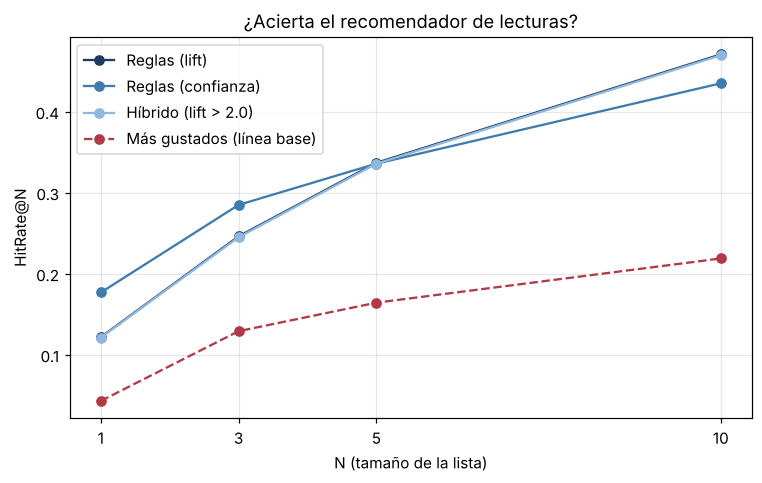

Mejora de reglas (lift) sobre la línea base: @1: ×2.8, @3: ×1.9, @5: ×2.1, @10: ×2.2


In [41]:
fig, ax = plt.subplots(figsize=(8, 4.5))
colores = [AZUL, "#3f7cac", "#8fb8de", ROJO]
for (nombre, serie), color in zip(hitrate.items(), colores):
    ax.plot(serie.index, serie.values, marker="o", color=color, label=nombre,
            linestyle="--" if "base" in nombre else "-")
ax.set_xlabel("N (tamaño de la lista)")
ax.set_ylabel("HitRate@N")
ax.set_xticks(N_LISTA)
ax.set_title("¿Acierta el recomendador de lecturas?")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

mejora = hitrate["Reglas (lift)"] / hitrate["Más gustados (línea base)"]
print("Mejora de reglas (lift) sobre la línea base:", ", ".join(f"@{N}: ×{v:.1f}" for N, v in mejora.items()))

In [42]:
# Sensibilidad del híbrido: ¿qué pasa si exigimos un lift mínimo más alto?
filas = []
for lift_min in [1.5, 2.0, 3.0, 4.0]:
    hr, activa, cobertura = hit_rate(casos, reglas_train, populares_train, orden="lift", lift_minimo=lift_min)
    filas.append({"lift mínimo": lift_min, "HitRate@5": hr[5], "HitRate@10": hr[10],
                  "% casos que usan reglas": activa, "cobertura": cobertura})
sensibilidad_hibrido = pd.DataFrame(filas)
sensibilidad_hibrido

,lift mínimo,HitRate@5,HitRate@10,% casos que usan reglas,cobertura
0,1.500,0.337,0.471,0.998,0.770
1,2.000,0.336,0.470,0.991,0.770
2,3.000,0.334,0.466,0.961,0.770
3,4.000,0.303,0.418,0.749,0.770


**Discusión de la evaluación**

| | @1 | @3 | @5 | @10 |
|---|---|---|---|---|
| Reglas (lift) | 0,122 | 0,246 | 0,337 | **0,471** |
| Reglas (confianza) | **0,177** | **0,285** | 0,336 | 0,435 |
| Híbrido (lift > 2) | 0,121 | 0,245 | 0,336 | 0,470 |
| Más gustados | 0,043 | 0,129 | 0,164 | 0,219 |

1. **Las reglas superan a la línea base en todos los N**: entre **1,9 y 2,8 veces** más aciertos (HitRate@10 = 0,47 vs 0,22). Recomendar lo más popular falla porque los lectores en general **ya leyeron** los libros más populares.
2. **Confianza gana con listas cortas (N = 1, 3), lift gana con listas largas (N = 10):** la confianza apuesta por libros populares (más probables); el lift sugiere libros más específicos, que aciertan menos en el primer puesto pero aportan más en una lista de 10.
3. **Cobertura (top-10):** lift recomienda el **77 %** del catálogo, confianza el **71 %** y los más gustados solo el **41 %**. Es el dilema **precisión vs. novedad**: la confianza es algo más precisa arriba, el lift reparte la recomendación entre más libros.
4. **Híbrido:** casi idéntico al de reglas puro, porque el **99 %** de los lectores de prueba activa alguna regla con lift > 2 (lectores con 14 libros en promedio). Al exigir lift > 4, solo el 75 % usa reglas y el HitRate@10 cae a 0,42: en esta base **conviene confiar en las reglas** y dejar la popularidad solo para el arranque en frío.
5. **% de casos con regla activa: 100 %** para las reglas (el respaldo de populares completa la lista cuando hay pocas reglas).

## 8. Hallazgos y recomendaciones

**Hallazgos**
1. Las asociaciones más fuertes (lift 4–9) son **dentro de la misma saga** (*Twilight*, *Harry Potter*, *Game of Thrones*): el 95,8 % de las reglas con minsop 0,10 son del mismo autor. Son ciertas, pero poco novedosas.
2. Hay asociaciones **entre autores** con lift 1,7–3,5 que sí sirven para descubrir lecturas: distopías (*1984* ⇒ *Brave New World*), fantasía (*Tolkien* ⇒ *Narnia*, *Harry Potter*), juvenil (*Divergent* ⇒ *The Hunger Games*).
3. Una confianza alta no basta: *{The Alchemist} ⇒ {The Hunger Games}* tiene confianza 0,375 y lift 1,05 (solo refleja popularidad).
4. Con ≥ 975 lectores por regla todas pasan Fisher + Holm; el filtro que más discrimina es el lift. La redundancia es baja con umbrales altos (2 de 1.836) y mayor con umbrales bajos (811 de 6.123).
5. El recomendador por reglas acierta **≈ 2 veces más** que recomendar lo más popular (HitRate@10 = 0,47 vs 0,22) y cubre el 77 % del catálogo.

**Recomendaciones para la biblioteca o librería**
- Usar el recomendador ordenado por **lift** en la sección "Te puede gustar" (lista de 5–10 títulos), **excluyendo los libros de la misma saga** si se busca descubrimiento.
- Usar las reglas de saga para **gestión de inventario**: cuando sube la demanda del libro 1, preparar ejemplares de los siguientes.
- Armar **listas temáticas** con las reglas entre autores (distopías clásicas, fantasía épica, juvenil contemporáneo).
- Para lectores nuevos o con favoritos fuera del catálogo, usar el respaldo de populares y pedir 2–3 libros favoritos al registrarse.

**Limitaciones**
- Solo los 100 libros más gustados y una muestra de 10.000 lectores: los libros de nicho no se recomiendan nunca.
- "Gustar" = 4 o 5 estrellas: un umbral distinto (solo 5) cambiaría las reglas.
- Las reglas no consideran el **orden** de lectura ni el contenido de los libros; la evaluación leave-one-out oculta un libro al azar, no "el próximo" que leerá.

## 9. Exportación de CSV para el dashboard
El dashboard (`app.py`) **no mina reglas**: lee estos archivos desde la carpeta `data/`.
Los conjuntos se guardan como texto separado por `" | "` para poder reconstruirlos.

In [43]:
import os
os.makedirs("data", exist_ok=True)

# Reglas del recomendador (todo el conjunto) con Fisher + Holm y marca de redundancia
exportar = reglas_rec.copy()
exportar["p_valor"] = [p_valor_fisher(x, z) for x, z in zip(exportar["antecedents"], exportar["consequents"])]
exportar["significativa"], exportar["p_ajustado"], _, _ = multipletests(exportar["p_valor"], method="holm")

# Redundancia por consecuente (más rápido que comparar todas contra todas)
exportar["redundante"] = False
for _, grupo in exportar.groupby("producto"):
    exportar.loc[grupo.index, "redundante"] = marcar_redundantes(grupo)

def a_texto(itemset):
    return " | ".join(sorted(itemset))

reglas_csv = pd.DataFrame({
    "antecedente": exportar["antecedents"].apply(a_texto),
    "consecuente": exportar["consequents"].apply(a_texto),
    "n_antecedente": exportar["antecedents"].apply(len),
    "soporte": exportar["support"], "confianza": exportar["confidence"], "lift": exportar["lift"],
    "leverage": exportar["leverage"], "conviccion": exportar["conviction"].replace(np.inf, 999),
    "p_ajustado": exportar["p_ajustado"], "significativa": exportar["significativa"],
    "redundante": exportar["redundante"],
}).sort_values("lift", ascending=False)
reglas_csv.to_csv("data/reglas.csv", index=False)

populares_csv = pd.DataFrame({"libro": soporte_libro.index, "soporte": soporte_libro.values,
                              "lectores": lectores.sum()[soporte_libro.index].values,
                              "autor": autor_de[soporte_libro.index].values})
populares_csv.to_csv("data/populares.csv", index=False)

hitrate_csv = hitrate.reset_index().melt(id_vars="N", var_name="estrategia", value_name="hitrate")
hitrate_csv.to_csv("data/hitrate.csv", index=False)

resumen_eval.rename_axis("estrategia").reset_index().to_csv("data/cobertura.csv", index=False)

resumen_csv = pd.DataFrame({"indicador": ["transacciones", "items", "densidad", "promedio_items",
                                          "reglas_recomendador", "casos_prueba"],
                            "valor": [len(lectores), lectores.shape[1], densidad, libros_por_lector.mean(),
                                      len(reglas_csv), len(casos)]})
resumen_csv.to_csv("data/resumen.csv", index=False)

for archivo in sorted(os.listdir("data")):
    print(f"data/{archivo}: {os.path.getsize('data/' + archivo) / 1024:.0f} KB")
print(f"\nReglas exportadas: {len(reglas_csv):,} | significativas: {reglas_csv['significativa'].sum():,} | "
      f"redundantes: {reglas_csv['redundante'].sum():,}")

data/cobertura.csv: 0 KB
data/hitrate.csv: 1 KB
data/populares.csv: 6 KB
data/reglas.csv: 1227 KB
data/resumen.csv: 0 KB

Reglas exportadas: 6,123 | significativas: 6,034 | redundantes: 811


In [44]:
# En Colab: descargar la carpeta data/ comprimida para subirla al repositorio
try:
    from google.colab import files
    import shutil
    shutil.make_archive("data", "zip", "data")
    files.download("data.zip")
except ImportError:
    print("No estamos en Colab: los CSV quedaron en la carpeta data/")

No estamos en Colab: los CSV quedaron en la carpeta data/
